In [59]:
# Импортируем библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import shapely
import os
import seaborn as sns

from statsmodels.tsa.arima.model import ARIMA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Задача 1

In [60]:
# Загружаем примерный набор данных по добыче нефти и газа
data = pd.DataFrame({
    'Date': pd.date_range(start='1/1/2020', periods=1200, freq='ME'),
    'Oil_Production': np.random.randint(100, 200, 1200),
    'Gas_Production': np.random.randint(300, 500, 1200)
})
# Основные статистики
# data.describe()
data.to_excel("Датасет.xlsx")
data.head()

,Date,Oil_Production,Gas_Production
0,2020-01-31,191,358
1,2020-02-29,129,453
2,2020-03-31,192,408
3,2020-04-30,145,325
4,2020-05-31,105,346


In [61]:
# TODO
# 1 заменить импорт данных на загрузку из excel файла (можно на примере реальных данных из интернета)
# 2 добавить массив давлений
# 3 построить кривую давления (температуры) на общем с добычей графике (ось давлений должна быть справа)

data = pd.read_excel("Датасет.xlsx", index_col=0)
data["Date"] = pd.to_datetime(data["Date"])

# Массив давлений: плавное снижение по мере накопленной добычи
np.random.seed(42)
cumulative = data["Oil_Production"].cumsum()
decline = (cumulative - cumulative.min()) / (cumulative.max() - cumulative.min())
data["Pressure"] = np.round(28 - 8 * decline + np.random.normal(0, 0.25, len(data)), 2)

data.head()

,Date,Oil_Production,Gas_Production,Pressure
0,2020-01-31,191,358,28.12
1,2020-02-29,129,453,27.96
2,2020-03-31,192,408,28.15
3,2020-04-30,145,325,28.36
4,2020-05-31,105,346,27.92


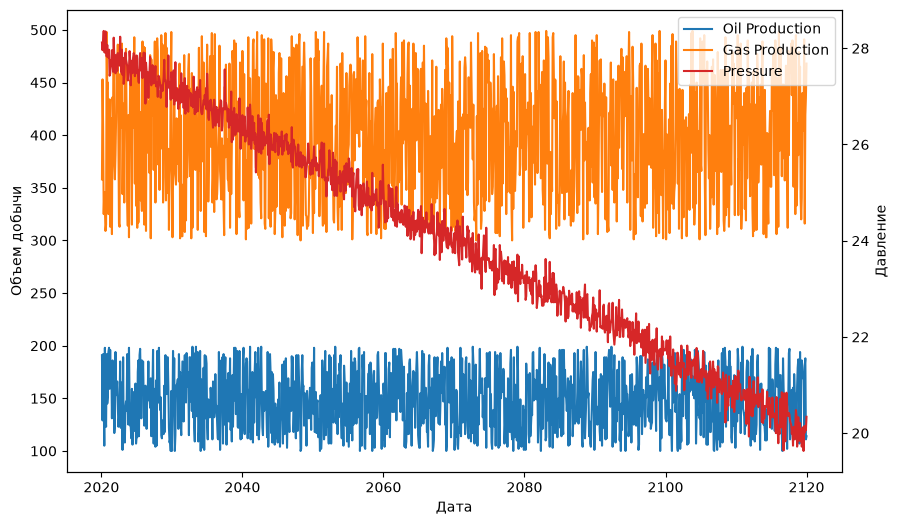

In [62]:
# Динамика добычи и давления (ось давления справа)
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(data["Date"], data["Oil_Production"], label="Oil Production")
ax1.plot(data["Date"], data["Gas_Production"], label="Gas Production")
ax1.set_xlabel("Дата")
ax1.set_ylabel("Объем добычи")

ax2 = ax1.twinx()
ax2.plot(data["Date"], data["Pressure"], color="tab:red", label="Pressure")
ax2.set_ylabel("Давление")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
plt.show()

# Задача 2

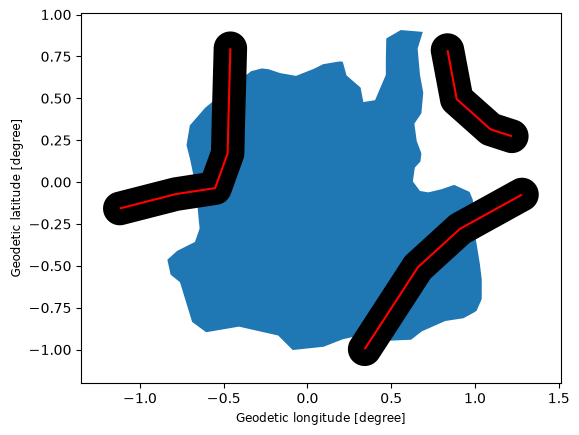

In [63]:
# shape file ESRI, geojson
# Загрузка данных месторождений
fields = gpd.read_file(os.path.join("input","oil_fields_shapefile.shp"))
# fields.head()

# Загрузка данных дорог
roads = gpd.read_file(os.path.join("input","roads.shp"))
# Буфер в метрах: слой в градусах (EPSG:4326), 0.1° ≈ 11.1 км
roads_projected = roads.to_crs(roads.estimate_utm_crs())
roads2 = roads_projected.buffer(11_132).to_crs(roads.crs)
# roads.head()

# Отображение данных на карте
fig, ax = plt.subplots()
fields.plot(ax=ax)
roads2.plot(ax=ax, color='k')
roads.plot(ax=ax, color='red')
plt.show()

   id_1  id_2   nam                                           geometry
0     1     1  None  LINESTRING (-0.66407 -0.05318, -0.55125 -0.035...
1     2     1  None  LINESTRING (0.99275 -0.23363, 0.91046 -0.27908...
Число пересечений: 2


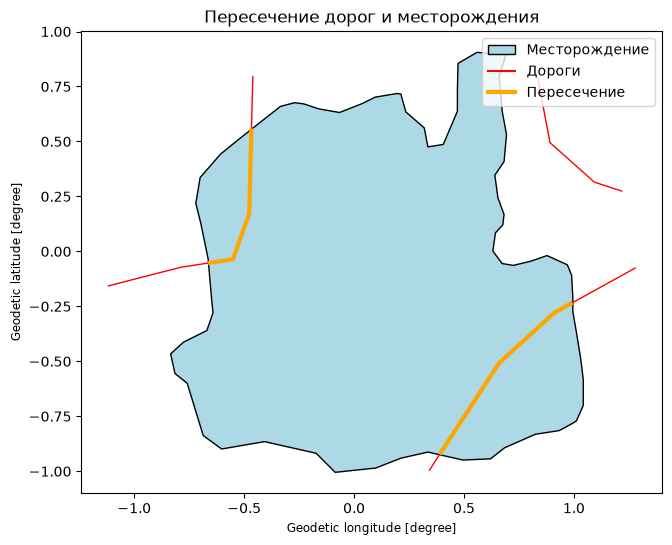

In [64]:
# TODO
# 1 построить пересечение слоев
# 2 вывести результат пересечения

# Пересечение дорог и контура месторождения
intersection = gpd.overlay(roads, fields, how="intersection", keep_geom_type=False)
print(intersection)
print("Число пересечений:", len(intersection))

fig, ax = plt.subplots(figsize=(8, 6))
fields.plot(ax=ax, color="lightblue", edgecolor="black")
roads.plot(ax=ax, color="red", linewidth=1)
intersection.plot(ax=ax, color="orange", linewidth=3)
ax.set_title("Пересечение дорог и месторождения")
ax.legend(
    handles=[
        plt.matplotlib.patches.Patch(facecolor="lightblue", edgecolor="black", label="Месторождение"),
        plt.matplotlib.lines.Line2D([0], [0], color="red", label="Дороги"),
        plt.matplotlib.lines.Line2D([0], [0], color="orange", linewidth=3, label="Пересечение"),
    ]
)
plt.show()

# Задача 3

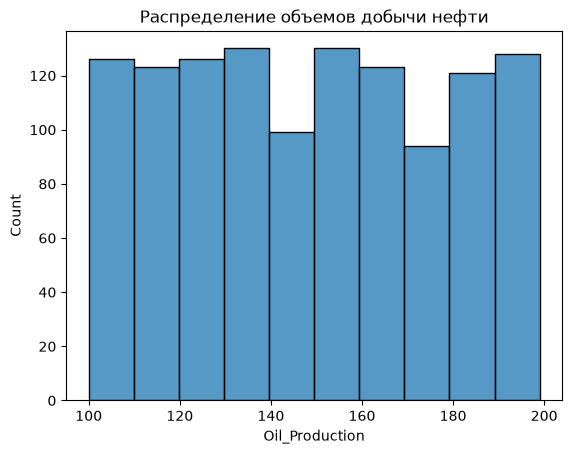

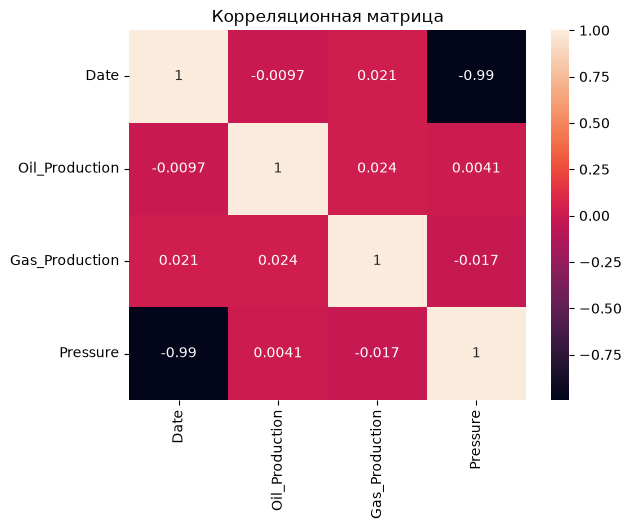

In [65]:
# Построение гистограммы распределения добычи
sns.histplot(data['Oil_Production'], bins=10)
plt.title("Распределение объемов добычи нефти")
plt.show()

# Анализ корреляций
sns.heatmap(data.corr(), annot=True)
plt.title("Корреляционная матрица")
plt.show()

                Oil_Production  Gas_Production  Pressure
Oil_Production        1.000000        0.023706  0.004050
Gas_Production        0.023706        1.000000 -0.017206
Pressure              0.004050       -0.017206  1.000000


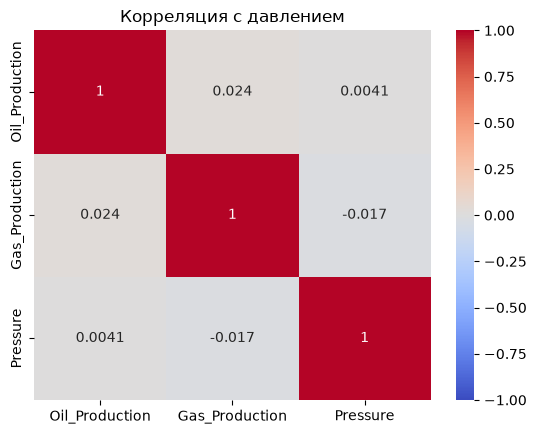

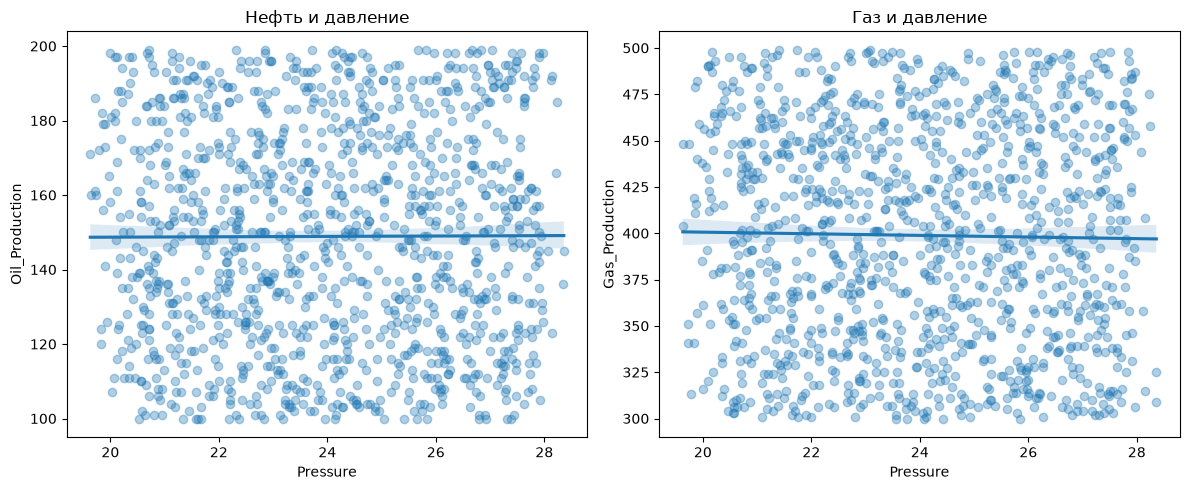

In [66]:
# TODO
# 1 Построить корреляцию с давлением

# Корреляция добычи нефти и газа с давлением
cols = ["Oil_Production", "Gas_Production", "Pressure"]
corr = data[cols].corr()
print(corr)

sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляция с давлением")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.regplot(data=data, x="Pressure", y="Oil_Production", ax=axes[0], scatter_kws={"alpha": 0.35})
axes[0].set_title("Нефть и давление")
sns.regplot(data=data, x="Pressure", y="Gas_Production", ax=axes[1], scatter_kws={"alpha": 0.35})
axes[1].set_title("Газ и давление")
plt.tight_layout()
plt.show()

# Задача 4

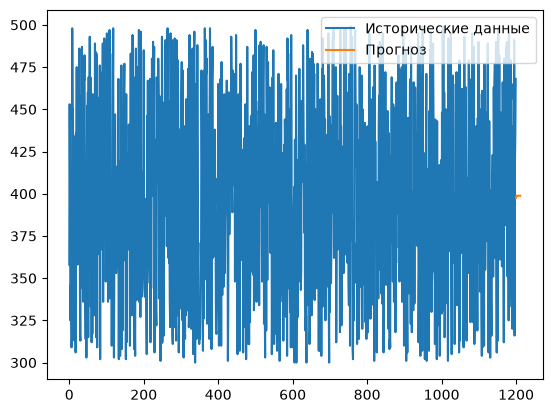

In [67]:
# Задача: Прогнозирование объемов добычи с использованием ARIMA

# Обучение модели
model = ARIMA(data['Gas_Production'], order=(1, 1, 1))
model_fit = model.fit()

# Прогноз
forecast = model_fit.forecast(steps=12)
plt.plot(data['Gas_Production'], label="Исторические данные")
plt.plot(forecast, label="Прогноз")
plt.legend()
plt.show()

MAE ARIMA: 51.92
MAE Holt (ExponentialSmoothing): 51.13
MAE SARIMAX: 51.85


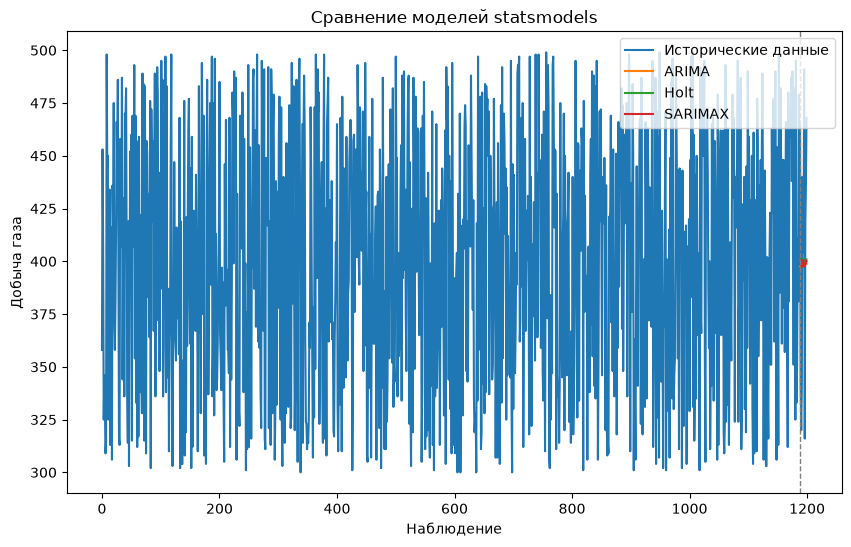

In [68]:
# TODO
# 1 Изучить другие модели из модуля statsmodels

# Сравнение ARIMA с другими моделями statsmodels: Holt и SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

series = data["Gas_Production"].astype(float)
horizon = 12
train = series.iloc[:-horizon]
test = series.iloc[-horizon:]

arima_forecast = ARIMA(train, order=(1, 1, 1)).fit().forecast(horizon)
holt_forecast = ExponentialSmoothing(train, trend="add").fit().forecast(horizon)
sarimax_forecast = SARIMAX(
    train, order=(1, 1, 1), seasonal_order=(1, 0, 0, 12)
).fit(disp=False).forecast(horizon)

def mae(actual, predicted):
    return float(np.mean(np.abs(np.asarray(actual) - np.asarray(predicted))))

print(f"MAE ARIMA: {mae(test, arima_forecast):.2f}")
print(f"MAE Holt (ExponentialSmoothing): {mae(test, holt_forecast):.2f}")
print(f"MAE SARIMAX: {mae(test, sarimax_forecast):.2f}")

plt.figure(figsize=(10, 6))
plt.plot(series.index, series.values, label="Исторические данные")
plt.plot(test.index, arima_forecast.values, label="ARIMA")
plt.plot(test.index, holt_forecast.values, label="Holt")
plt.plot(test.index, sarimax_forecast.values, label="SARIMAX")
plt.axvline(test.index[0], color="gray", linestyle="--", linewidth=1)
plt.xlabel("Наблюдение")
plt.ylabel("Добыча газа")
plt.title("Сравнение моделей statsmodels")
plt.legend()
plt.show()

# Задача 5

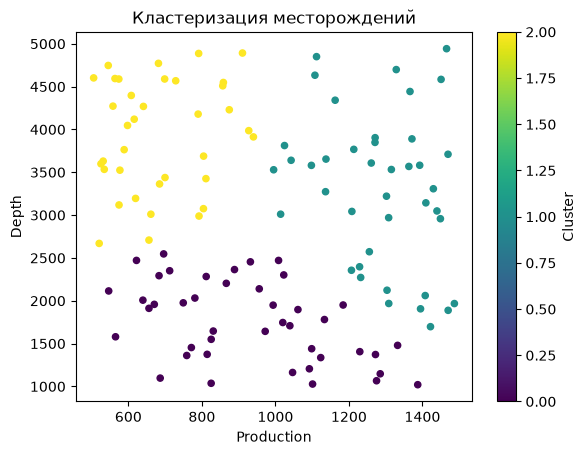

In [69]:
# Генерация случайных данных
np.random.seed(42)
num_samples = 120

data = {
    'Production': np.random.uniform(500, 1500, num_samples),
    'Depth': np.random.uniform(1000, 5000, num_samples)
}

fields_2 = pd.DataFrame(data)

# Вывод первых строк сгенерированных данных
# fields_2.head(10)


# Стандартизация данных
scaler = StandardScaler()
data_scaled = scaler.fit_transform(fields_2[['Production', 'Depth']])


# Кластеризация
kmeans = KMeans(n_clusters=3, random_state=42)
fields_2['Cluster'] = kmeans.fit_predict(data_scaled)

# Визуализация кластеров
fields_2.plot(kind='scatter', x='Production', y='Depth', c='Cluster', colormap='viridis', colorbar=True)
plt.title("Кластеризация месторождений")
plt.show()


Inertia: {2: np.float64(141.33), 3: np.float64(82.53), 4: np.float64(50.62), 5: np.float64(42.8), 6: np.float64(36.73), 7: np.float64(29.8), 8: np.float64(25.61)}
Silhouette: {2: np.float64(0.372), 3: np.float64(0.423), 4: np.float64(0.446), 5: np.float64(0.407), 6: np.float64(0.37), 7: np.float64(0.377), 8: np.float64(0.392)}
Оптимальное число кластеров по silhouette: 4


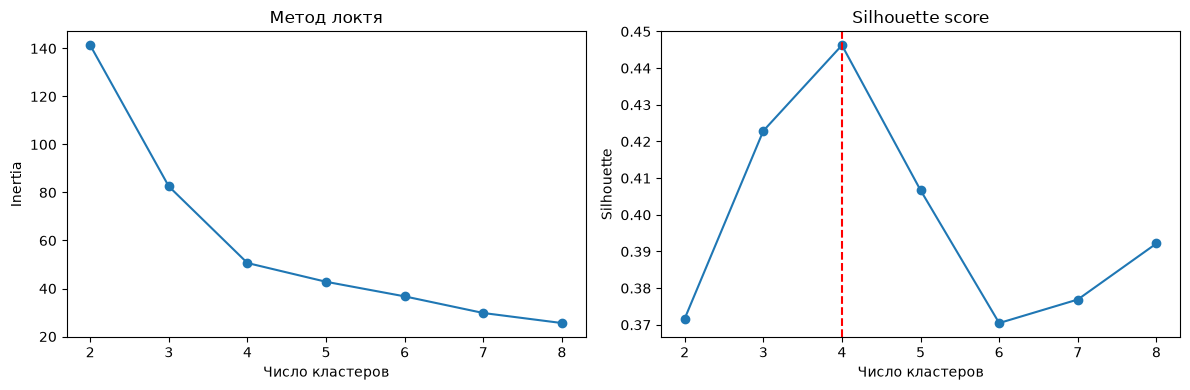

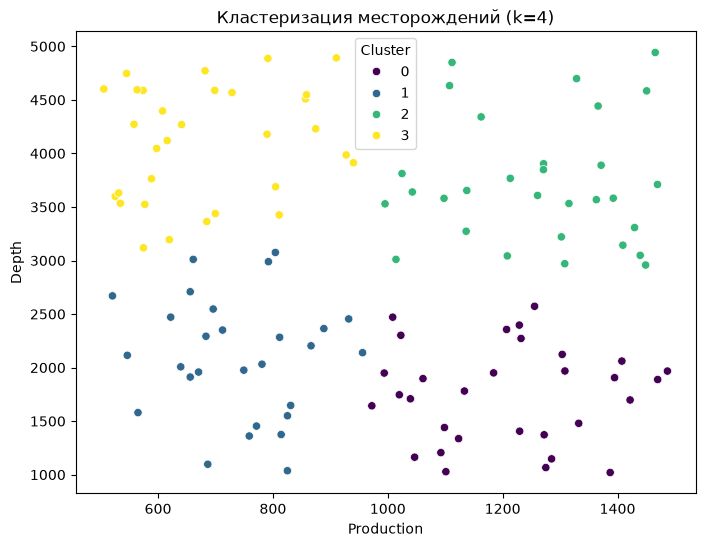

In [70]:
# TODO
# 1 Добавить проверки оптимального количества кластеров.
# 2 Измененить визуализацию с использованием библиотеки pyplot или seaborn для более гибких графиков.

# Подбор числа кластеров: метод локтя и silhouette
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
inertias = []
silhouettes = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(data_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(data_scaled, labels))

best_k = list(k_values)[int(np.argmax(silhouettes))]
print("Inertia:", dict(zip(k_values, np.round(inertias, 2))))
print("Silhouette:", dict(zip(k_values, np.round(silhouettes, 3))))
print("Оптимальное число кластеров по silhouette:", best_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("Число кластеров")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o")
axes[1].axvline(best_k, color="red", linestyle="--")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Число кластеров")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

fields_2["Cluster"] = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(data_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=fields_2, x="Production", y="Depth", hue="Cluster", palette="viridis")
plt.title(f"Кластеризация месторождений (k={best_k})")
plt.show()